# 02 — Exploratory Data Analysis (EDA) — OSA clinical data

**Input:** `../data/processed/OSA_DB_UPM_BMI_classes.xlsx` (output of `src/01_data_preparation.py`)
**Output:** figures in `../figures/` for Section 3 of the PRDL and MLLB reports.

Questions:
1. What does the distribution of IAH look like? (choice of regression target)
2. Which clinical variables are related to IAH, and how strongly? (hypotheses H1, H2)
3. Do the variables separate Healthy (IAH ≤ 10) and Severe (IAH ≥ 30) patients?
4. Are men and women different? (why classification uses men only)
5. Are some predictors redundant? (Weight, Height, BMI)
6. How do patients look in 2D (PCA)?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

DATA = Path("../data/processed/OSA_DB_UPM_BMI_classes.xlsx")
FIG = Path("../figures")
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Healthy": "#2a9d8f", "Intermediate": "#bdbdbd", "Severe": "#e76f51"}
GENDER_PAL = {"hombre": "#457b9d", "mujer": "#e9a03b"}

df = pd.read_excel(DATA)
predictors = ["Weight", "Height", "BMI", "Age", "Cervical"]
print(df.shape)
df.head()

(637, 9)


,Patient,Gender,IAH,Weight,Height,Age,Cervical,BMI,OSA
0,P0002,hombre,29.6,119,174,56,48.0,39.305060,Intermediate
1,P0004,hombre,19.7,78,168,39,42.0,27.636054,Intermediate
2,P0005,hombre,9.0,80,173,32,40.0,26.729927,Healthy
3,P0006,hombre,2.0,109,190,32,42.0,30.193906,Healthy
4,P0007,hombre,34.0,86,169,39,42.0,30.110991,Severe


## 1. Summary statistics

In [2]:
summary = df[["IAH"] + predictors].describe().T.round(1)
summary.to_csv(FIG.parent / "results" / "eda_summary.csv") if (FIG.parent / "results").exists() else None
summary

,count,mean,std,min,25%,50%,75%,max
IAH,637.0,20.4,18.6,0.0,6.4,14.4,30.0,108.6
Weight,637.0,87.7,18.4,45.0,75.0,86.0,98.0,165.0
Height,637.0,171.3,9.6,144.0,165.0,171.0,178.0,197.0
BMI,637.0,29.9,5.6,18.3,26.0,28.7,32.8,63.7
Age,637.0,49.5,12.4,20.0,40.0,49.0,59.0,88.0
Cervical,637.0,40.6,4.0,30.0,38.0,41.0,43.0,53.0


In [3]:
print(df["Gender"].value_counts(), "\n")
print(pd.crosstab(df["OSA"], df["Gender"], margins=True))

Gender
hombre    455
mujer     182
Name: count, dtype: int64 

Gender        hombre  mujer  All
OSA                             
Healthy          141    101  242
Intermediate     177     52  229
Severe           137     29  166
All              455    182  637


## 2. Distribution of the target IAH
IAH is a count per hour, so a right-skewed distribution is expected. If it is strongly skewed, a log transform `log(1 + IAH)` may help regression models.

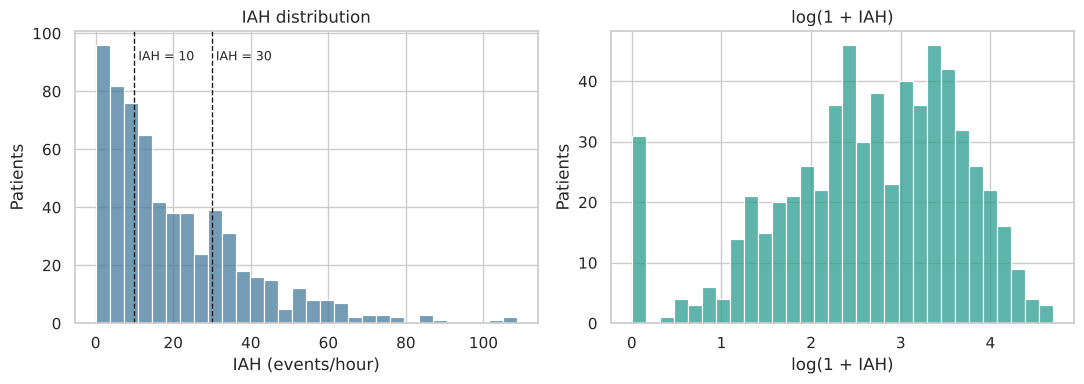

Skewness IAH: 1.45   log(1+IAH): -0.66
Patients with IAH = 0: 31


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["IAH"], bins=30, ax=axes[0], color="#457b9d")
for t, lab in [(10, "IAH = 10"), (30, "IAH = 30")]:
    axes[0].axvline(t, ls="--", color="k", lw=1)
    axes[0].text(t + 1, axes[0].get_ylim()[1] * 0.9, lab, fontsize=9)
axes[0].set(title="IAH distribution", xlabel="IAH (events/hour)", ylabel="Patients")
sns.histplot(np.log1p(df["IAH"]), bins=30, ax=axes[1], color="#2a9d8f")
axes[1].set(title="log(1 + IAH)", xlabel="log(1 + IAH)", ylabel="Patients")
plt.tight_layout(); plt.savefig(FIG / "eda_01_iah_distribution.png", dpi=200); plt.show()

print(f"Skewness IAH: {stats.skew(df['IAH']):.2f}   log(1+IAH): {stats.skew(np.log1p(df['IAH'])):.2f}")
print(f"Patients with IAH = 0: {(df['IAH'] == 0).sum()}")

## 3. Distribution of the predictors, by gender

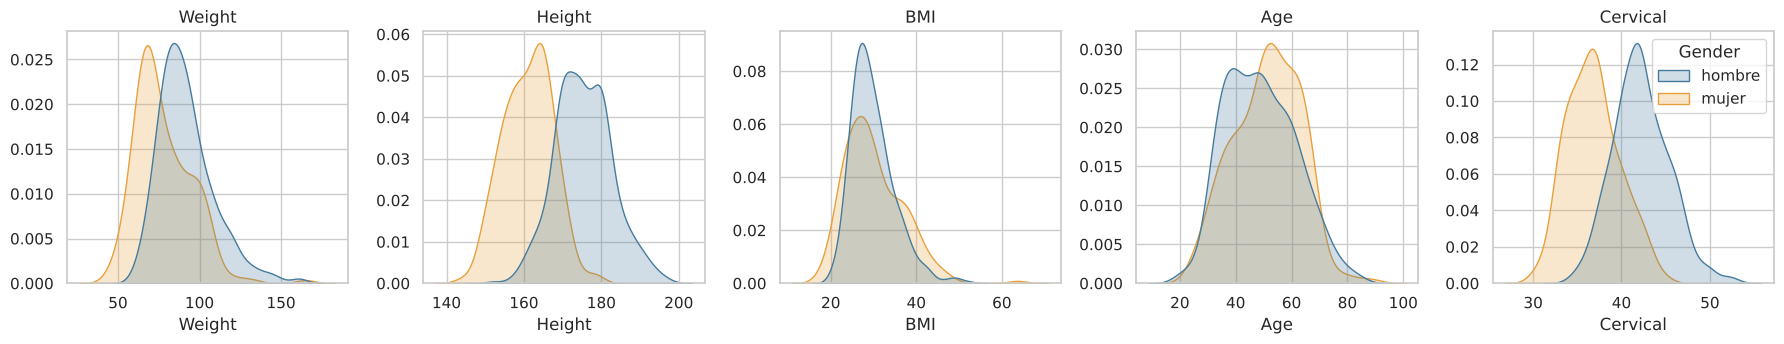

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
for ax, c in zip(axes, predictors):
    sns.kdeplot(data=df, x=c, hue="Gender", fill=True, common_norm=False, palette=GENDER_PAL, ax=ax, legend=(c == predictors[-1]))
    ax.set_title(c); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_02_predictors_by_gender.png", dpi=200); plt.show()

## 4. Relation between each predictor and IAH
Pearson measures a linear relation; Spearman measures a monotonic relation (robust to the skewness of IAH).

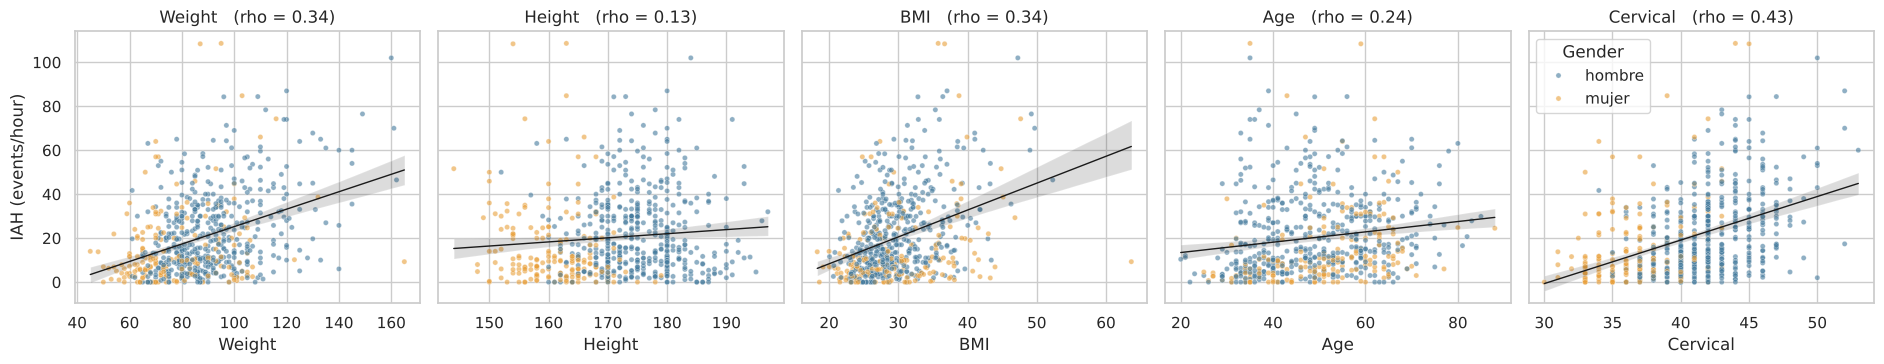

,Variable,Pearson r,p (Pearson),Spearman rho,p (Spearman)
4,Cervical,0.422,0.000,0.433,0.000
0,Weight,0.391,0.000,0.344,0.000
2,BMI,0.370,0.000,0.337,0.000
3,Age,0.157,0.000,0.240,0.000
1,Height,0.096,0.015,0.133,0.001


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.8), sharey=True)
rows = []
for ax, c in zip(axes, predictors):
    sns.scatterplot(data=df, x=c, y="IAH", hue="Gender", palette=GENDER_PAL, s=14, alpha=0.6, ax=ax, legend=(c == predictors[-1]))
    sns.regplot(data=df, x=c, y="IAH", scatter=False, color="k", line_kws={"lw": 1}, ax=ax)
    r, p = stats.pearsonr(df[c], df["IAH"]); rho, ps = stats.spearmanr(df[c], df["IAH"])
    rows.append({"Variable": c, "Pearson r": r, "p (Pearson)": p, "Spearman rho": rho, "p (Spearman)": ps})
    ax.set_title(f"{c}   (rho = {rho:.2f})")
axes[0].set_ylabel("IAH (events/hour)")
plt.tight_layout(); plt.savefig(FIG / "eda_03_predictors_vs_iah.png", dpi=200); plt.show()

corr_iah = pd.DataFrame(rows).sort_values("Spearman rho", ascending=False)
corr_iah.round(3)

In [7]:
# Same correlations, men and women separately
by_gender = pd.DataFrame({g: [stats.spearmanr(d[c], d["IAH"])[0] for c in predictors]
                          for g, d in df.groupby("Gender")}, index=predictors).round(2)
by_gender.columns = [f"Spearman rho ({g})" for g in by_gender.columns]
by_gender

,Spearman rho (hombre),Spearman rho (mujer)
Weight,0.32,0.19
Height,-0.01,-0.17
BMI,0.39,0.25
Age,0.23,0.41
Cervical,0.39,0.28


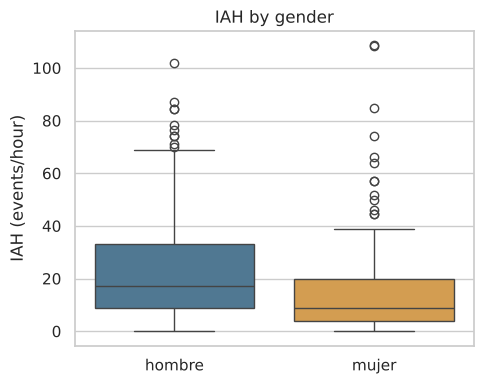

Median IAH  men: 17.2  women: 8.9  Mann-Whitney p = 1.4e-09


In [8]:
# IAH by gender
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df, x="Gender", y="IAH", hue="Gender", palette=GENDER_PAL, legend=False, ax=ax)
ax.set(title="IAH by gender", ylabel="IAH (events/hour)", xlabel="")
plt.tight_layout(); plt.savefig(FIG / "eda_04_iah_by_gender.png", dpi=200); plt.show()
u, p = stats.mannwhitneyu(df.loc[df.Gender == "hombre", "IAH"], df.loc[df.Gender == "mujer", "IAH"])
print(f"Median IAH  men: {df.loc[df.Gender=='hombre','IAH'].median():.1f}  women: {df.loc[df.Gender=='mujer','IAH'].median():.1f}  Mann-Whitney p = {p:.1e}")

## 5. Redundancy between predictors
Weight, Height and BMI are linked by definition (BMI = Weight / Height²). Strong correlations between predictors make linear-model coefficients unstable (multicollinearity).

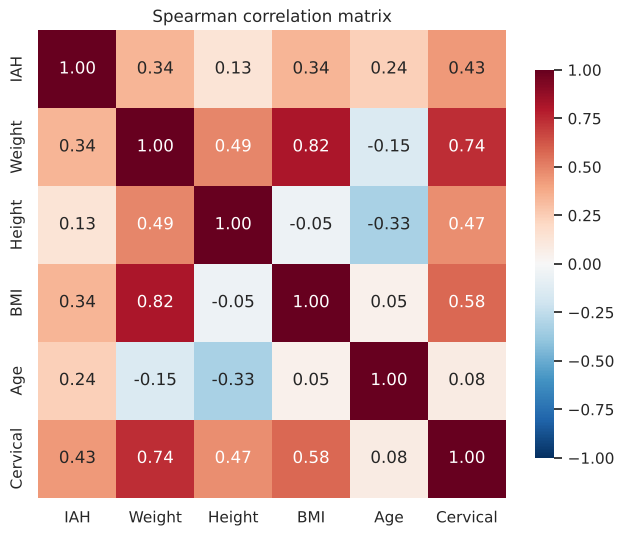

In [9]:
corr = df[["IAH"] + predictors].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlation matrix")
plt.tight_layout(); plt.savefig(FIG / "eda_05_correlation_matrix.png", dpi=200); plt.show()

## 6. Healthy vs Severe (classification dataset: extreme cases, men only)
Same subset as `OSA_extreme_male.xlsx`. Mann-Whitney U test: are the two classes different for each variable?

{'Healthy': 141, 'Severe': 137}


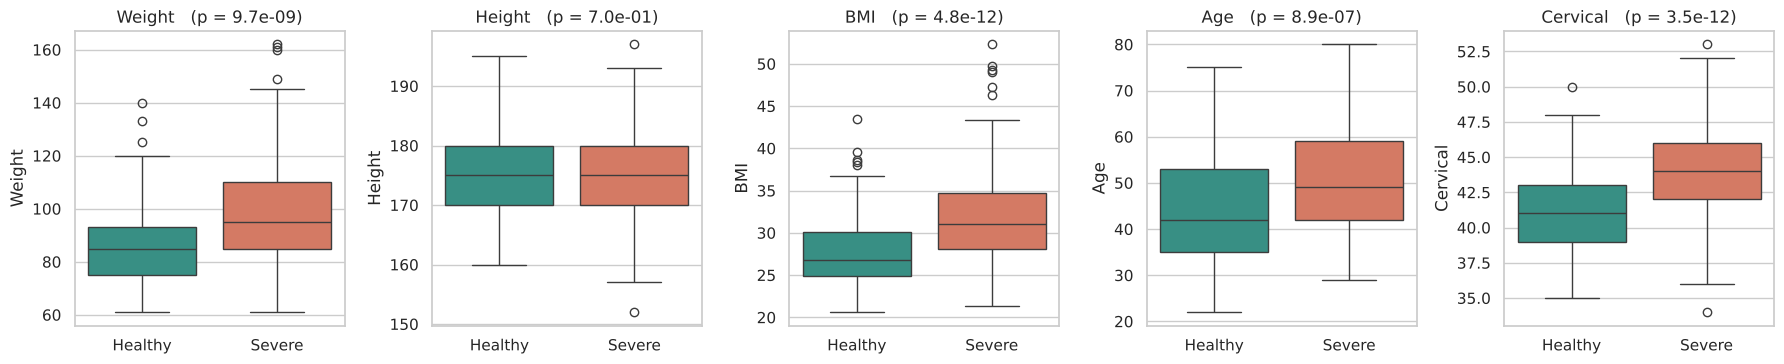

,Variable,Median Healthy,Median Severe,Mann-Whitney p
0,Weight,85.0000,95.000,0.0000
1,Height,175.0000,175.000,0.7008
2,BMI,26.8136,31.055,0.0000
3,Age,42.0000,49.000,0.0000
4,Cervical,41.0000,44.000,0.0000


In [10]:
ext = df[(df["OSA"] != "Intermediate") & (df["Gender"] == "hombre")]
print(ext["OSA"].value_counts().to_dict())

fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
rows = []
for ax, c in zip(axes, predictors):
    sns.boxplot(data=ext, x="OSA", y=c, hue="OSA", order=["Healthy", "Severe"], palette=PALETTE, legend=False, ax=ax)
    h, s = ext.loc[ext.OSA == "Healthy", c], ext.loc[ext.OSA == "Severe", c]
    u, p = stats.mannwhitneyu(h, s)
    rows.append({"Variable": c, "Median Healthy": h.median(), "Median Severe": s.median(), "Mann-Whitney p": p})
    ax.set_title(f"{c}   (p = {p:.1e})"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_06_healthy_vs_severe_male.png", dpi=200); plt.show()
pd.DataFrame(rows).round(4)

## 7. PCA: the patients in two dimensions
PCA on the standardised predictors (no IAH, no class). Colouring by class shows whether the classes separate without supervision.

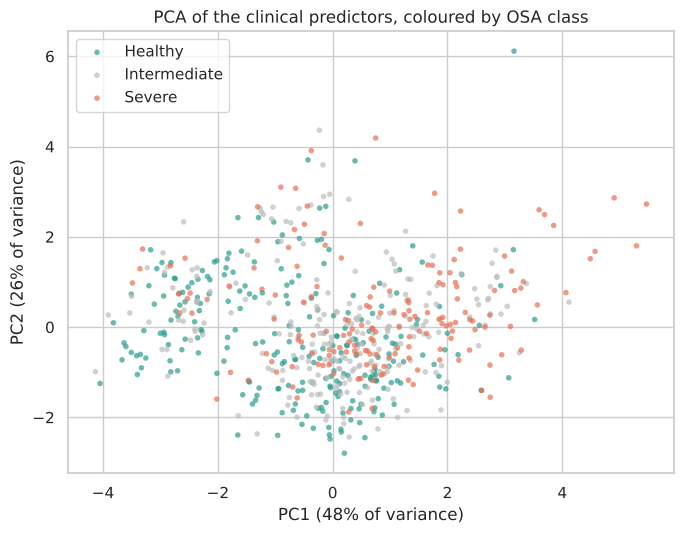

,PC1,PC2
Weight,0.53,0.27
Height,0.39,-0.51
BMI,0.35,0.61
Age,-0.09,0.34
Cervical,0.52,0.09
Male,0.40,-0.42


In [11]:
X = StandardScaler().fit_transform(df[predictors + []].assign(Male=(df.Gender == "hombre").astype(int)))
pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
ev = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 5.5))
for cls in ["Healthy", "Intermediate", "Severe"]:
    m = df["OSA"] == cls
    ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.7, c=PALETTE[cls], label=cls, edgecolor="none")
ax.set(xlabel=f"PC1 ({ev[0]:.0%} of variance)", ylabel=f"PC2 ({ev[1]:.0%} of variance)",
       title="PCA of the clinical predictors, coloured by OSA class")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "eda_07_pca.png", dpi=200); plt.show()

loadings = pd.DataFrame(pca.components_.T, index=predictors + ["Male"], columns=["PC1", "PC2"]).round(2)
loadings

## 8. Conclusions of the EDA
*(to be written in the report from the outputs above — see the summary given with this notebook)*